# Notebook 05 — Machine Learning: Clustering and Simple Regression

Notebook 04 showed that neighbouring areas really do differ, far more than their margins of error allow, and the worst pairs are 14 to 16 years apart. 14 to 16 years. I find that remarkable. Two places that share a boundary, and the people in one can expect well over a decade more of good health than the people next door. I find that pattern interesting, and this notebook is where I start asking why that discrepancy exists.

I've got seven measures for each area, chosen in [Notebook 03](../C%20%E2%80%94%20Joined%20Table%20and%20Exploration/03_Joined_Table_and_Exploration.ipynb): income after housing costs, qualifications, employment, fuel poverty, NO₂, recorded crime and anti-social behaviour. So the question is this. If I know those seven things about a place, how much of its HLE can I guess? And when two neighbours are far apart, is it because they're different kinds of place on paper, or do they look alike and still differ?

I come at it two ways.

**Part A, clustering.** I sort the areas into groups using only the seven measures. HLE is kept out, so the groups can't just be HLE in disguise. Then I bring HLE back and see whether the groups differ.

**Part B, regression.** I fit one straight-line model that predicts HLE from the same seven measures, and I test it on local authorities it hasn't seen. The areas it gets most wrong are the ones I care about most. They're the places where something my measures don't capture is going on.

### Why these two methods

I picked k-means for the clustering because each group has a centre, a sort of average area for that group, and I can describe that in plain words. I picked a plain linear regression because it gives me one number per measure, in years of HLE, and I can explain every one of them. A fancier model might squeeze out a bit more accuracy, but I'd struggle to say what it was doing. For this project I'd rather understand the answer.

I did look at the alternatives. For grouping, hierarchical clustering gives a tree of groups, but with 654 areas the tree is hard to read and I'd still have to choose where to cut it. DBSCAN looks for dense clumps and calls everything else noise, and my areas don't sit in clumps: they run along one long slope, so it would probably find one big group. A Gaussian mixture allows groups of different shapes, but its groups are harder to describe in plain words than a k-means centre. For prediction, ridge or lasso regression would steady the weights if the measures overlapped badly, but my overlap checks in section 2 stay well under the stop lines, so a plain regression is fine. A random forest or gradient boosting might predict a little better, but neither gives one clear weight per measure, and here explaining the answer matters more to me than the last bit of accuracy. A spatial regression would build the neighbour effect into the model. I deal with that instead by testing on whole local authorities the model hasn't seen, and by checking what pattern is left on the map at the end.

My outcome is the average of male and female HLE, the same as in every notebook since 01. The neighbour tables come from [Notebook 04](../D%20%E2%80%94%20Hypothesis%20and%20Neighbour%20Gaps/04_Hypothesis_and_Neighbour_Gaps.ipynb). I read both without changing them.

## Setting up

Imports, file paths and a few fixed settings. The seed (42) means the random parts give the same answer every time I run this. Everything saves to one Machine Learning folder and overwrites on each run.

In [1]:
from pathlib import Path
import sys
import json
import textwrap

import numpy as np
import pandas as pd
import geopandas as gpd
import sklearn
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.colors import ListedColormap, TwoSlopeNorm
from matplotlib.patches import Patch
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict
from sklearn.metrics import (silhouette_score, adjusted_rand_score, mean_squared_error,
                             mean_absolute_error, r2_score)

%matplotlib inline


# Find the project from the notebook's current folder. My working copy uses Data/, the GitHub copy uses data/.
project_folder = next(p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / "Data/Cleaned/Wide/msoa_wide_660.csv").is_file()
                      or (p / "data/cleaned/Wide/msoa_wide_660.csv").is_file())
data_folder = project_folder / ("Data" if (project_folder / "Data").is_dir() else "data")


# In the GitHub copy the first folder is lowercase (data/raw, data/cleaned), so I lower it to match.
def project_data(relative_path):
    parts = Path(relative_path).parts
    if data_folder.name == "data":
        parts = (parts[0].lower(), *parts[1:])
    return data_folder.joinpath(*parts)


# Enforce the project environment in the working copy. A GitHub clone has no bundled .venv.
expected_environment = project_folder / "VS_CODE/.venv"
if expected_environment.is_dir():
    assert Path(sys.prefix).resolve() == expected_environment.resolve(), "Select the project virtual environment."


# Raw source files sit in the project's raw folder, wherever the project is copied.
def raw_file(filename):
    candidates = sorted(project_data("Raw").rglob(filename))
    if not candidates:
        raise FileNotFoundError(f"Raw source not found in the project's raw folder: {filename}")
    return candidates[0]

output_folder = project_data("Cleaned/Machine Learning")
figure_folder = project_data("Cleaned/Machine Learning/figures")
figure_folder.mkdir(parents=True, exist_ok=True)

# Fixed settings, kept together so I can see them in one place.
SEED = 42
EXPECTED_AREAS = 660
EXPECTED_MODEL_AREAS = 654
K_VALUES = list(range(2, 9))
MIN_CHOSEN_K = 3
N_INIT = 20
BOOTSTRAPS = 50
MIN_STABILITY = 0.70
FOLDS = 5
MORAN_PERMUTATIONS = 999


def read_csv(relative):
    return pd.read_csv(project_data(relative))


# Same pattern as Notebook 04: write the file, read it back, check it matches.
def save_csv(table, filename, index=False):
    path = output_folder / filename
    with path.open("w", encoding="utf-8", newline="") as stream:
        table.to_csv(stream, index=index)
    check = pd.read_csv(path)
    expected = table.reset_index() if index else table.reset_index(drop=True)
    pd.testing.assert_frame_equal(check, expected, check_dtype=False)


def save_figure(figure, filename):
    path = figure_folder / filename
    figure.savefig(path, bbox_inches="tight")
    assert path.is_file() and path.stat().st_size > 0
    plt.show()
    plt.close(figure)


sns.set_theme(style="whitegrid", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150,
                     "axes.spines.top": False, "axes.spines.right": False})

print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")
print("I save to:", output_folder.relative_to(project_folder).as_posix())

Python 3.14.7 | scikit-learn 1.9.1 | pandas 3.0.6
I save to: Data/Cleaned/Machine Learning


## 1. The areas and the seven measures

The seven measures are the ones I picked in Notebook 03 as the best single stand-in for each theme. I left household deprivation out on purpose. It includes a health and disability element, and using health to predict health would be cheating. Ethnic composition is out too, for now, to keep this first model simple.

Six areas sit out: the city and town centres with no usable crime figure. Their crime numbers are swollen by shoppers and visitors, so they tell me about footfall more than about the people who live there. They stay in the data and on the maps, hatched grey.

In [2]:
# The wide table from Notebook 03: one row per area.
wide = read_csv("Cleaned/Wide/msoa_wide_660.csv").sort_values("area_code").reset_index(drop=True)
assert len(wide) == EXPECTED_AREAS and wide["area_code"].is_unique


# The seven measures marked as representatives in Notebook 03's review table.
# Deprivation and the ethnicity shares must not be among them.
review = read_csv("Cleaned/Wide/theme_representatives_for_review.csv")
representatives = review.loc[review["decision"].eq("Provisional representative")].copy()
features = representatives["measure"].tolist()
assert len(features) == 7 and len(set(features)) == len(features)
assert "households_deprived_2plus_pct" not in features
assert not any(c.startswith(("asian_", "black_", "mixed_", "white_", "other_")) for c in features)
assert "crime_for_analysis" in features


# Each area needs exactly one local authority, because Part B splits the data by authority.
lookup = read_csv("Prepared/Geography/ons_lsoa21_to_msoa21_lad22_exploratory_west_midlands.csv")
lookup = lookup[["MSOA21CD", "LAD22CD", "LAD22NM"]].drop_duplicates()
assert lookup.notna().all().all()
assert lookup.groupby("MSOA21CD")["LAD22CD"].nunique().eq(1).all()

authority_lookup = lookup.drop_duplicates("MSOA21CD").rename(columns={
    "MSOA21CD": "area_code", "LAD22CD": "authority_code", "LAD22NM": "authority_name"})
areas = wide.merge(authority_lookup, on="area_code", how="left", validate="one_to_one")
assert len(areas) == EXPECTED_AREAS
assert areas[["authority_code", "authority_name"]].notna().all().all()

In [3]:
# The six city and town centres with a blank crime figure sit out of the modelling.
excluded = areas.loc[areas["crime_for_analysis"].isna(), ["area_code", "local_area_name", "authority_name"]].copy()
assert len(excluded) == EXPECTED_AREAS - EXPECTED_MODEL_AREAS
assert areas.loc[areas["crime_for_analysis"].isna(), "visitor_hub"].all()

model_areas = areas.loc[areas["crime_for_analysis"].notna()].reset_index(drop=True)
assert len(model_areas) == EXPECTED_MODEL_AREAS and model_areas["area_code"].is_unique
assert model_areas[[*features, "hle_average"]].notna().all().all()


# Each measure's label, unit and period, for the tables.
feature_dictionary = read_csv("Cleaned/Wide/data_dictionary.csv").set_index("column")
feature_labels = representatives.set_index("measure")["label"].to_dict()
feature_units = feature_dictionary.loc[features, "unit"].to_dict()

measure_table = representatives[["theme", "measure", "label"]].copy()
measure_table["unit"] = measure_table["measure"].map(feature_units)
measure_table["period"] = measure_table["measure"].map(feature_dictionary["period"])

display(measure_table.reset_index(drop=True))

print(f"I include {len(model_areas)} areas and leave out {len(excluded)} city and town centres.")

display(excluded.reset_index(drop=True))

print("HLE period:", ", ".join(wide["hle_period"].unique()))

,theme,measure,label,unit,period
0,Socioeconomic,annual_equivalised_income_after_housing_costs_gbp,Household income after housing costs,£ per year,FYE March 2023
1,Education,level4plus_pct,Level 4+ qualifications,% residents aged 16+,2021
2,Safety,crime_for_analysis,Recorded crime (visitor hubs omitted),"published rows / 1,000 residents",2024 / population 2021
3,Housing,fuel_poor_households_pct,Fuel-poor households,% households,2024
4,Environment,no2_area_mean_ug_m3,NO₂ area mean,µg/m³,2024
5,Labour market,employed_residents_16plus_pct,Employed residents aged 16+,% residents aged 16+,2021
6,Safety,asb_rows_per_1000_residents,Anti-social behaviour rate,"published rows / 1,000 residents",2024 / population 2021


I include 654 areas and leave out 6 city and town centres.


,area_code,local_area_name,authority_name
0,E02001876,Birmingham Dartmouth Circus,Birmingham
1,E02001988,Central Coventry,Coventry
2,E02002139,Walsall Central,Walsall
3,E02002168,Wolverhampton Central,Wolverhampton
4,E02006896,Digbeth,Birmingham
5,E02006899,Birmingham city centre,Birmingham


HLE period: 2019–2023


That leaves 654 areas. The six that sit out are Birmingham Dartmouth Circus, Digbeth and Birmingham city centre, plus Central Coventry, Walsall Central and Wolverhampton Central.

HLE covers 2019 to 2023. The other measures come from 2021 to 2024, so this isn't one snapshot in time. For comparing areas with each other, it's close enough.

## 2. Do the measures overlap too much?

Before fitting anything, I check whether any of the measures are telling me the same thing twice. If two of them move together closely, the model can't tell them apart, and the weight it gives each one becomes unreliable.

I use two checks. Spearman correlation looks at pairs: do two measures rank the areas in the same order? VIF (variance inflation factor) looks at each measure against the other six together: how well can they predict it? My stop lines are a Spearman above 0.80 or a VIF above 10. HLE isn't involved in either check.

In [4]:
# X is the seven measures, y is HLE, and groups says which authority each area belongs to.
X = model_areas[features]
y = model_areas["hle_average"].to_numpy()
groups = model_areas["authority_code"].to_numpy()


# The largest correlation between two different measures. The diagonal (each measure with itself) is zeroed.
spearman = X.corr(method="spearman")
off_diagonal = spearman.to_numpy(copy=True)
np.fill_diagonal(off_diagonal, 0)
max_spearman = float(np.abs(off_diagonal).max())
assert max_spearman < 0.80, "Two measures overlap past the stop line."


# A shortcut: the diagonal of the inverted correlation matrix gives each measure's VIF directly.
pearson_matrix = np.corrcoef(X.to_numpy(), rowvar=False)
vif_values = np.diag(np.linalg.inv(pearson_matrix))
vif_table = pd.DataFrame({"measure": features, "label": [feature_labels[f] for f in features], "vif": vif_values})
assert vif_values.max() <= 10, "A measure is past the VIF stop line."

display(spearman.rename(index=feature_labels, columns=feature_labels).round(2))

print(f"Largest Spearman correlation between two measures: {max_spearman:.3f}")

display(vif_table.round(2))

,Household income after housing costs,Level 4+ qualifications,Recorded crime (visitor hubs omitted),Fuel-poor households,NO₂ area mean,Employed residents aged 16+,Anti-social behaviour rate
Household income after housing costs,1.00,0.76,-0.71,-0.68,-0.59,0.55,-0.44
Level 4+ qualifications,0.76,1.00,-0.46,-0.39,-0.38,0.37,-0.32
Recorded crime (visitor hubs omitted),-0.71,-0.46,1.00,0.54,0.60,-0.35,0.67
Fuel-poor households,-0.68,-0.39,0.54,1.00,0.38,-0.50,0.28
NO₂ area mean,-0.59,-0.38,0.60,0.38,1.00,-0.46,0.12
Employed residents aged 16+,0.55,0.37,-0.35,-0.50,-0.46,1.00,-0.08
Anti-social behaviour rate,-0.44,-0.32,0.67,0.28,0.12,-0.08,1.00


Largest Spearman correlation between two measures: 0.759


,measure,label,vif
0,annual_equivalised_income_after_housing_costs_gbp,Household income after housing costs,5.62
1,level4plus_pct,Level 4+ qualifications,2.45
2,crime_for_analysis,Recorded crime (visitor hubs omitted),3.39
3,fuel_poor_households_pct,Fuel-poor households,2.37
4,no2_area_mean_ug_m3,NO₂ area mean,2.22
5,employed_residents_16plus_pct,Employed residents aged 16+,1.84
6,asb_rows_per_1000_residents,Anti-social behaviour rate,2.25


Nothing hits a stop line. The closest pair is income and qualifications at 0.76, and income has the highest VIF at 5.6. That makes sense: better-paid areas tend to be better-qualified ones. So all seven stay in, but when I read the regression weights I'll remember that income and qualifications are partly sharing the credit.

## Part A — Clustering

### 3. How many groups?

K-means needs me to say how many groups I want. It drops that many centre points into the data, puts each area with its nearest centre, moves each centre to the middle of its areas, and repeats until nothing moves.

First, I put all seven measures on the same scale. Income is in pounds and NO₂ is in micrograms, so without this, income would swamp everything just because its numbers are bigger. After scaling, every measure has an average of 0 and a typical spread (standard deviation) of 1.

To choose the number of groups I use the silhouette score. For each area it asks how much closer it is to its own group than to the next nearest one. 1 means clearly in the right place. 0 means sitting on the fence. I try 2 to 8 groups and take the best score from 3 upwards. I skip 2 on purpose. Two groups would almost certainly split into better-off and worse-off, and I don't need k-means to tell me that.

,k,silhouette
0,2,0.317
1,3,0.232
2,4,0.234
3,5,0.183
4,6,0.194
5,7,0.193
6,8,0.203


Chosen: 4 groups. Difference between three and four groups: 0.0021


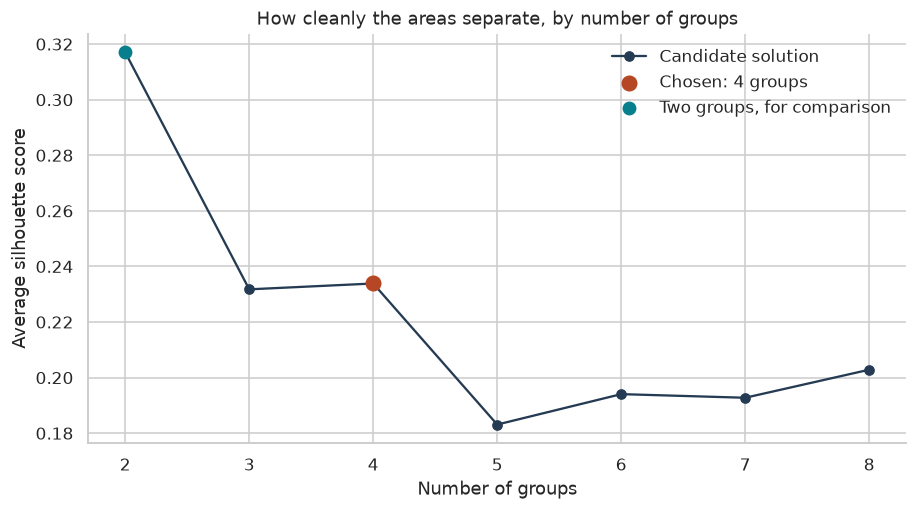

In [5]:
# Clustering only describes these areas, so the scaling uses all of them.
# Part B scales inside each training batch instead.
cluster_scaler = StandardScaler()
scaled_profiles = cluster_scaler.fit_transform(X)


# Try two to eight groups. Silhouette asks how much closer each area sits to its own group than to the next.
cluster_models = {}
silhouette_rows = []
for k in K_VALUES:
    fitted = KMeans(n_clusters=k, random_state=SEED, n_init=N_INIT).fit(scaled_profiles)
    cluster_models[k] = fitted
    silhouette_rows.append({"k": k, "silhouette": float(silhouette_score(scaled_profiles, fitted.labels_))})

silhouette_table = pd.DataFrame(silhouette_rows)

# Two groups would just be better off against worse off, so the choice starts at three.
eligible = silhouette_table.loc[silhouette_table["k"].ge(MIN_CHOSEN_K)]
chosen_k = int(eligible.sort_values(["silhouette", "k"], ascending=[False, True]).iloc[0]["k"])
chosen_model = cluster_models[chosen_k]
chosen_silhouette = float(silhouette_table.set_index("k").loc[chosen_k, "silhouette"])
k3_k4_difference = float(abs(silhouette_table.set_index("k").loc[3, "silhouette"]
                             - silhouette_table.set_index("k").loc[4, "silhouette"]))


fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.plot(silhouette_table["k"], silhouette_table["silhouette"], marker="o", color="#243b53",
        label="Candidate solution")
ax.scatter([chosen_k], [chosen_silhouette], color="#b54724", s=90, zorder=3, label=f"Chosen: {chosen_k} groups")
ax.scatter([2], [silhouette_table.iloc[0]["silhouette"]], color="#087f8c", s=65, zorder=3,
           label="Two groups, for comparison")
ax.set(xticks=K_VALUES, xlabel="Number of groups", ylabel="Average silhouette score",
       title="How cleanly the areas separate, by number of groups")
ax.legend(frameon=False)
fig.tight_layout()

display(silhouette_table.round(3))

print(f"Chosen: {chosen_k} groups. Difference between three and four groups: {k3_k4_difference:.4f}")

save_figure(fig, "01_silhouette_scores.png")

Two groups do score best (0.32), as expected. From three upwards, four groups edges it at 0.234 against 0.232 for three. That's basically a tie, so I show both in the comparison later.

These scores are low. Anything under about 0.5 means the groups aren't clearly separate. My areas don't fall into neat types. They sit along one long slope from worse-off to better-off, and the four groups are me cutting that slope into slices. That's still useful, as long as I remember the edges between the groups are soft.

### 4. Are the groups stable?

If the groups only appear because of a handful of particular areas, they aren't worth much. So I resample. I draw 654 areas at random with replacement, so some appear twice and some not at all. Then I redo the grouping and see how closely the new groups match the originals. I do that 50 times.

The match is measured with the adjusted Rand index (ARI). 1 means identical groups, 0 means no better than chance. My stop line is an average below 0.70.

In [6]:
# Resample the areas with replacement 50 times, re-run k-means each time,
# and see how often the same areas end up grouped together (ARI: 1 means identical, 0 means chance).
bootstrap_rng = np.random.default_rng(SEED)
stability_values = []
for _ in range(BOOTSTRAPS):
    sampled_positions = bootstrap_rng.integers(0, len(model_areas), size=len(model_areas))
    resampled = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=N_INIT).fit(scaled_profiles[sampled_positions])

    # Compare on all 654 areas, including any the resample happened to miss.
    resampled_labels = resampled.predict(scaled_profiles)
    stability_values.append(float(adjusted_rand_score(chosen_model.labels_, resampled_labels)))

stability_mean = float(np.mean(stability_values))
assert stability_mean >= MIN_STABILITY, "The groups are below the stability stop line."

print(f"Average ARI: {stability_mean:.2f}, ranging from {min(stability_values):.2f} to {max(stability_values):.2f} "
      f"over {BOOTSTRAPS} resamples.")

Average ARI: 0.80, ranging from 0.56 to 0.96 over 50 resamples.


The average ARI is 0.80, ranging from 0.56 to 0.96. So the groups mostly come back the same. A few resamples shuffle them more, which fits with the soft edges.

### 5. What the groups look like

I label each group by its two biggest differences from the average area. HLE plays no part in this. The heat map shows how far each group sits above or below average on each measure, in standard deviations. The table gives the actual values. I number the groups from lowest to highest average income.

In [7]:
# Renumber the groups by average income so Group 1 is always the lowest-income group.
raw_membership = chosen_model.labels_
raw_means = X.assign(raw_cluster=raw_membership).groupby("raw_cluster")[features].mean()
income_measure = representatives.loc[representatives["theme"].eq("Socioeconomic"), "measure"].iloc[0]
raw_order = raw_means[income_measure].sort_values().index.tolist()
cluster_id_lookup = {raw: rank + 1 for rank, raw in enumerate(raw_order)}
cluster_ids = np.array([cluster_id_lookup[raw] for raw in raw_membership])

# Each group's average on every measure: in real units, and in standard steps from the average area.
profile_means = X.assign(cluster_id=cluster_ids).groupby("cluster_id")[features].mean()
profile_z = (pd.DataFrame(scaled_profiles, columns=features)
             .assign(cluster_id=cluster_ids).groupby("cluster_id")[features].mean())
cluster_counts = pd.Series(cluster_ids).value_counts().sort_index()


# Each label comes from the group's two biggest departures from average. HLE is never used.
descriptor = {
    "annual_equivalised_income_after_housing_costs_gbp": ("Higher income", "Lower income"),
    "level4plus_pct": ("More qualifications", "Fewer qualifications"),
    "crime_for_analysis": ("Higher recorded crime", "Lower recorded crime"),
    "fuel_poor_households_pct": ("More fuel poverty", "Less fuel poverty"),
    "no2_area_mean_ug_m3": ("Higher NO₂", "Lower NO₂"),
    "employed_residents_16plus_pct": ("More employment", "Less employment"),
    "asb_rows_per_1000_residents": ("Higher ASB", "Lower ASB")}
assert set(descriptor) == set(features)

cluster_label_lookup = {}
for cluster_id, row in profile_z.iterrows():
    leading = row.abs().sort_values(ascending=False).head(2).index
    cluster_label_lookup[int(cluster_id)] = " / ".join(descriptor[f][0 if row[f] >= 0 else 1] for f in leading)
assert len(set(cluster_label_lookup.values())) == chosen_k, "Two groups ended up with the same label."
cluster_labels = [cluster_label_lookup[int(c)] for c in cluster_ids]


# Long table for saving: one row per group per measure.
profile_rows = []
for cluster_id in profile_means.index:
    for feature in features:
        profile_rows.append({"cluster_id": int(cluster_id), "cluster_label": cluster_label_lookup[int(cluster_id)],
            "area_count": int(cluster_counts.loc[cluster_id]), "measure": feature,
            "measure_label": feature_labels[feature], "unit": feature_units[feature],
            "mean": float(profile_means.loc[cluster_id, feature]),
            "standardised_mean": float(profile_z.loc[cluster_id, feature])})
cluster_profiles = pd.DataFrame(profile_rows)

# A readable version for the notebook, with units in the column names.
display_profiles = profile_means.rename(columns={f: feature_labels[f] + " (" + feature_units[f] + ")"
                                                 for f in features})
display_profiles.insert(0, "Areas", cluster_counts)
display_profiles.insert(0, "Profile label", pd.Series(cluster_label_lookup))

,Profile label,Areas,Household income after housing costs (£ per year),Level 4+ qualifications (% residents aged 16+),"Recorded crime (visitor hubs omitted) (published rows / 1,000 residents)",Fuel-poor households (% households),NO₂ area mean (µg/m³),Employed residents aged 16+ (% residents aged 16+),"Anti-social behaviour rate (published rows / 1,000 residents)"
cluster_id,,,,,,,,,
1,More fuel poverty / Less employment,105,24205.0,22.9,126.1,17.3,15.0,46.7,11.0
2,Higher ASB / Higher recorded crime,53,28485.2,27.5,165.5,12.8,10.5,56.1,24.6
3,Fewer qualifications / Lower income,247,29666.3,24.7,82.3,11.4,10.9,55.9,9.3
4,Higher income / More qualifications,249,36032.4,36.3,50.6,9.6,7.7,58.0,6.5


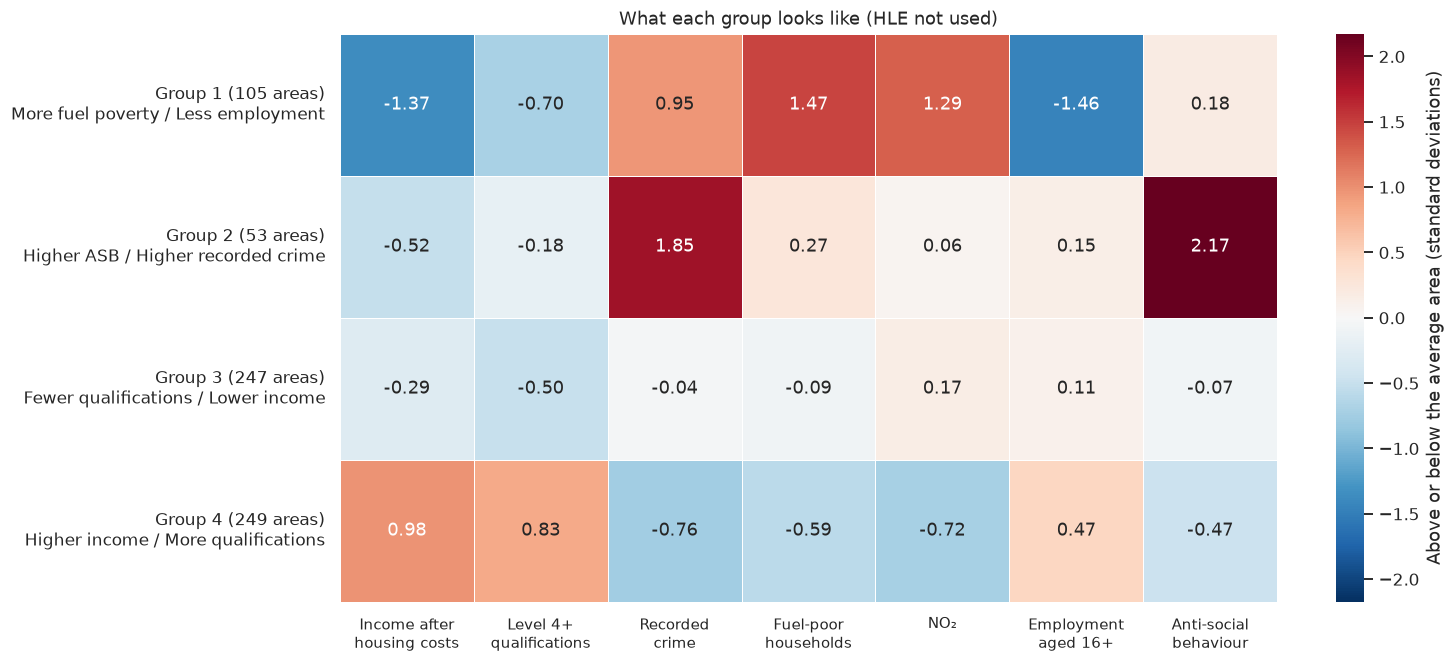

In [8]:
# Short, two-line names so the heatmap's columns fit.
short_labels = {
    "annual_equivalised_income_after_housing_costs_gbp": "Income after\nhousing costs",
    "level4plus_pct": "Level 4+\nqualifications", "crime_for_analysis": "Recorded\ncrime",
    "fuel_poor_households_pct": "Fuel-poor\nhouseholds", "no2_area_mean_ug_m3": "NO₂",
    "employed_residents_16plus_pct": "Employment\naged 16+", "asb_rows_per_1000_residents": "Anti-social\nbehaviour"}
row_labels = [f"Group {c} ({cluster_counts.loc[c]} areas)\n" + textwrap.fill(cluster_label_lookup[int(c)], 35)
              for c in profile_z.index]
heat = profile_z.rename(columns=short_labels).copy()
heat.index = row_labels

fig, ax = plt.subplots(figsize=(14.0, 6.2))

# The colour scale is symmetrical, so white is the average area, red above, blue below.
colour_limit = float(np.abs(heat.to_numpy()).max())
sns.heatmap(heat, cmap="RdBu_r", center=0, vmin=-colour_limit, vmax=colour_limit,
            annot=True, fmt=".2f", linewidths=.6, ax=ax,
            cbar_kws={"label": "Above or below the average area (standard deviations)"})
ax.set(title="What each group looks like (HLE not used)", xlabel="", ylabel="")
ax.tick_params(axis="x", rotation=0, labelsize=10)
ax.tick_params(axis="y", rotation=0)
fig.tight_layout()

display(display_profiles.round(1))

save_figure(fig, "02_cluster_profiles.png")

- **Group 1, more fuel poverty and less employment** (105 areas). The poorest group, with the lowest income. It also picks up some student areas, which look poor on paper because students earn little and mostly don't work.
- **Group 2, higher ASB and recorded crime** (53 areas). The odd one out. It's picked out by crime and anti-social behaviour, not by where it sits on income.
- **Group 3, fewer qualifications and lower income** (247 areas). Below average, but not as far below as Group 1.
- **Group 4, higher income and more qualifications** (249 areas). The better-off group.

Groups 1, 3 and 4 are slices of the same slope. Group 2 is the only one that's something different.

### 6. Now I bring HLE back

This is the real test of the grouping. The groups were built without HLE. If they still differ a lot on HLE, the seven measures are carrying a lot of the story.

I measure it as the share of all the variation in HLE that lies between the group averages rather than inside the groups. It only describes these 654 areas, because the groups were made from them. Testing on areas the model hasn't seen is Part B's job.

In [9]:
# HLE comes back in only now, to describe the groups that were made without it.
cluster_hle_summary = (pd.DataFrame({"cluster_id": cluster_ids, "hle_average": y})
                       .groupby("cluster_id")["hle_average"]
                       .agg(count="count", mean="mean", median="median", minimum="min", maximum="max")
                       .reset_index())
cluster_hle_summary.insert(1, "cluster_label", cluster_hle_summary["cluster_id"].map(cluster_label_lookup))
cluster_hle_summary["unit"] = "years"


# Giving every area its group's average HLE and scoring that is the same as the between-group share.
group_mean_prediction = pd.Series(cluster_ids).map(cluster_hle_summary.set_index("cluster_id")["mean"]).to_numpy()
cluster_hle_share = float(r2_score(y, group_mean_prediction))


# The same share for two, three and four groups, so I can see whether the choice matters.
comparison_rows = []
for k in sorted({2, chosen_k, 3, 4}):
    labels_k = cluster_models[k].labels_
    hle_means_k = pd.Series(y).groupby(labels_k).transform("mean").to_numpy()
    counts_k = pd.Series(labels_k).value_counts().sort_values().tolist()
    comparison_rows.append({"k": k, "silhouette": float(silhouette_table.set_index("k").loc[k, "silhouette"]),
        "group_sizes_smallest_first": ", ".join(str(v) for v in counts_k),
        "between_group_hle_share": float(r2_score(y, hle_means_k)), "selected": k == chosen_k})
cluster_comparison = pd.DataFrame(comparison_rows)

,cluster_id,cluster_label,count,mean,median,minimum,maximum,unit
0,1,More fuel poverty / Less employment,105,57.3,56.8,53.7,69.8,years
1,2,Higher ASB / Higher recorded crime,53,61.1,60.4,55.0,75.3,years
2,3,Fewer qualifications / Lower income,247,62.4,62.4,55.1,69.6,years
3,4,Higher income / More qualifications,249,68.9,69.0,62.6,75.7,years


Share of HLE variation between the groups: 70.6%


,k,silhouette,group_sizes_smallest_first,between_group_hle_share,selected
0,2,0.317,"272, 382",0.649,False
1,3,0.232,"126, 255, 273",0.722,False
2,4,0.234,"53, 105, 247, 249",0.706,True


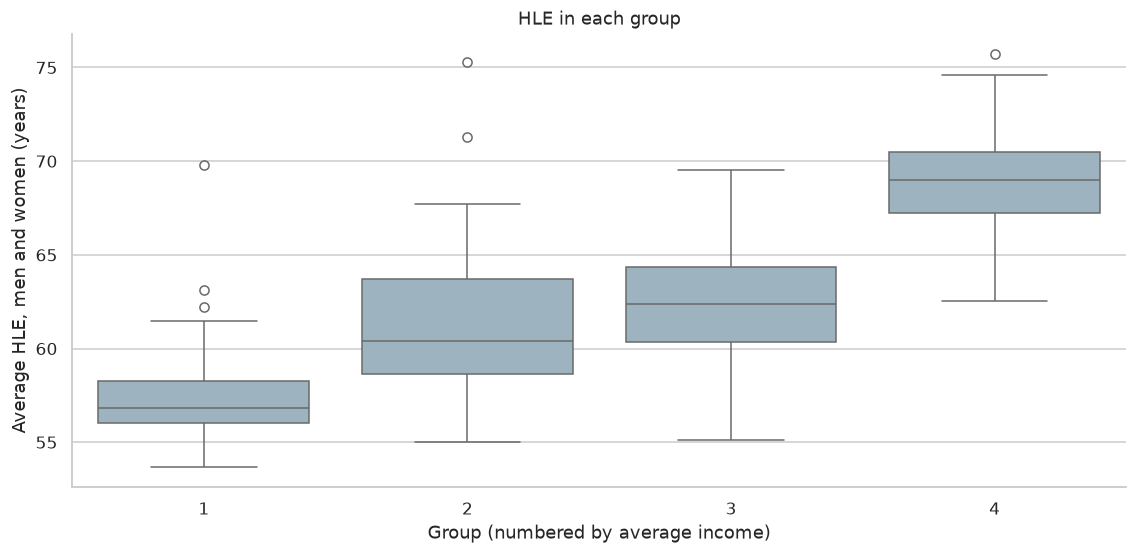

In [10]:
# Box plot of HLE in each group, then the summary table and the share of HLE variation between groups.
box_data = pd.DataFrame({"cluster_id": cluster_ids, "hle_average": y})

fig, ax = plt.subplots(figsize=(10.5, 5.2))
sns.boxplot(data=box_data, x="cluster_id", y="hle_average", color="#98b4c6", ax=ax)
ax.set(title="HLE in each group", xlabel="Group (numbered by average income)",
       ylabel="Average HLE, men and women (years)")
fig.tight_layout()

display(cluster_hle_summary.round(1))

print(f"Share of HLE variation between the groups: {100 * cluster_hle_share:.1f}%")

display(cluster_comparison.round(3))

save_figure(fig, "03_hle_by_cluster.png")

They differ a lot. The better-off group averages 68.9 years in good health. Group 1 averages 57.3. That's over 11 years between group averages, from groups that never saw HLE. Groups 2 and 3 sit in between, at 61.1 and 62.4.

The groups account for about 71% of the variation in HLE. Three groups would give 72% and two would give 65%, so the exact number of groups doesn't change the picture much.

The box plot shows the overlap as well. Every group has areas well above and below its average. Group 2 runs all the way from 55 to 75 years.

### 7. The groups on the map

Same boundaries as Notebook 04. The six city and town centres that sit out are hatched grey.

In [11]:
boundary_path = raw_file("ons_msoa21_boundaries_exploratory_west_midlands.geojson")
boundaries = gpd.read_file(boundary_path)

# Find the MSOA code column by its pattern rather than trusting a column name.
boundary_code_field = next(field for field in boundaries.columns if field != "geometry"
    and boundaries[field].astype(str).str.fullmatch(r"[EW]020\d{5}").all())
assert boundaries[boundary_code_field].is_unique and len(boundaries) == EXPECTED_AREAS
assert set(boundaries[boundary_code_field]) == set(areas["area_code"])

# British National Grid, so distances and shapes are in metres.
boundaries_by_code = boundaries.set_index(boundary_code_field).to_crs(27700)


# Each modelled area's group, joined onto its shape.
model_results = model_areas[["area_code"]].copy()
model_results["cluster_id"] = cluster_ids
model_results["cluster_label"] = cluster_labels
map_areas = boundaries_by_code.join(model_results.set_index("area_code"), how="left", validate="one_to_one")


# Shared map styling: kilometre axis labels, true shape, no grid.
def format_map(ax):
    ax.set(xlabel="Easting (km)", ylabel="Northing (km)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1000:.0f}"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value / 1000:.0f}"))
    ax.set_aspect("equal")
    ax.grid(False)

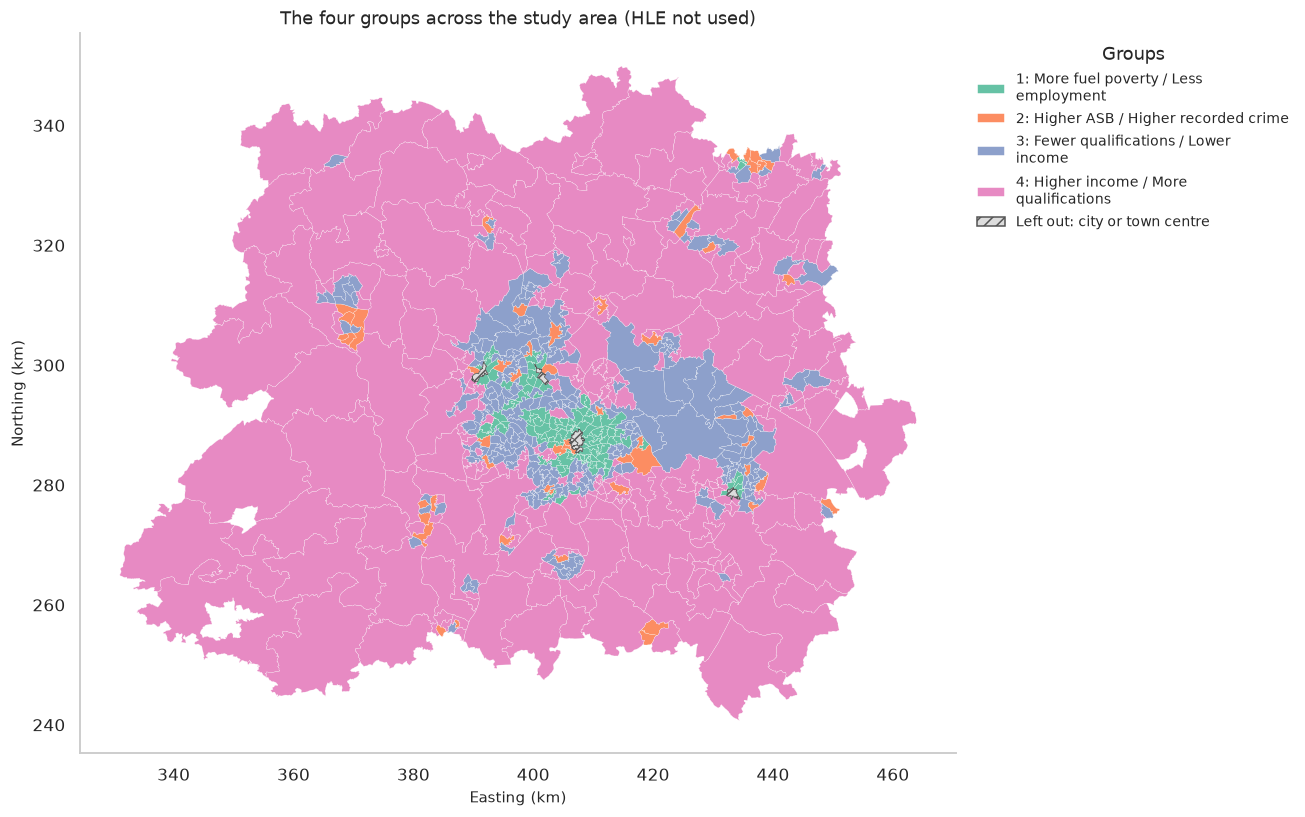

In [12]:
palette = sns.color_palette("Set2", n_colors=chosen_k)

fig, ax = plt.subplots(figsize=(11, 8))

# Grouped areas in their colours; the six centres hatched grey.
included_map = map_areas.loc[map_areas["cluster_id"].notna()]
excluded_map = map_areas.loc[map_areas["cluster_id"].isna()]
included_map.plot(column="cluster_id", categorical=True, cmap=ListedColormap(palette), ax=ax,
                  edgecolor="#ffffff", linewidth=.15)
excluded_map.plot(ax=ax, facecolor="#dddddd", edgecolor="#555555", linewidth=.5, hatch="///")

handles = [Patch(facecolor=palette[c - 1], label=f"{c}: " + textwrap.fill(cluster_label_lookup[c], 34))
           for c in range(1, chosen_k + 1)]
handles.append(Patch(facecolor="#dddddd", hatch="///", edgecolor="#555555", label="Left out: city or town centre"))
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, title="Groups", fontsize=9)
format_map(ax)
ax.set_title("The four groups across the study area (HLE not used)")
fig.tight_layout()

save_figure(fig, "04_cluster_map.png")

### 8. Back to the big-gap neighbours

Now the question I started with. Notebook 04 picked out 95 big-gap neighbour pairs. If two neighbours with a huge HLE gap fall in different groups, the gap goes along with them being different kinds of place. If they fall in the same group, they look broadly alike on paper and still differ. That's harder to explain.

On its own, the number of pairs that cross groups doesn't mean much. Plenty of ordinary neighbours cross groups too, especially with edges this soft. So I compare the big-gap pairs with all neighbour pairs.

In [13]:
membership_by_code = model_results.set_index("area_code")["cluster_id"]


# Every neighbour pair where both areas are in the modelling, as the comparison.
neighbour_pairs = read_csv("Cleaned/Neighbours/neighbour_pairs.csv")
assert len(neighbour_pairs) == 1885 and not neighbour_pairs.duplicated(["area_a", "area_b"]).any()
both_included = (neighbour_pairs["area_a"].isin(membership_by_code.index)
                 & neighbour_pairs["area_b"].isin(membership_by_code.index))
all_pairs = neighbour_pairs.loc[both_included].copy()
all_pairs_cross = all_pairs["area_a"].map(membership_by_code).ne(all_pairs["area_b"].map(membership_by_code))
all_pairs_cross_share = float(all_pairs_cross.mean())


# The big-gap pairs: do their two sides fall in different groups?
big_pairs = read_csv("Cleaned/Neighbours/big_gap_pairs.csv")
assert len(big_pairs) == 95 and not big_pairs.duplicated(["area_a", "area_b"]).any()
eligible_big = big_pairs["area_a"].isin(membership_by_code.index) & big_pairs["area_b"].isin(membership_by_code.index)
eligible_big_pairs = big_pairs.loc[eligible_big].copy()
different_cluster = (eligible_big_pairs["area_a"].map(membership_by_code)
                     .ne(eligible_big_pairs["area_b"].map(membership_by_code)))
big_pair_different = int(different_cluster.sum())
big_pair_same = int((~different_cluster).sum())


crossing = pd.DataFrame([
    {"pairs": "All neighbour pairs", "count": len(all_pairs), "cross_groups": int(all_pairs_cross.sum()),
     "share_crossing": all_pairs_cross_share},
    {"pairs": "Big-gap pairs", "count": len(eligible_big_pairs), "cross_groups": big_pair_different,
     "share_crossing": big_pair_different / len(eligible_big_pairs)}])

display(crossing.round(3))

print(f"{int((~eligible_big).sum())} big-gap pairs can't be classified because one area is a city or town centre:")

display(big_pairs.loc[~eligible_big, ["name_a", "name_b", "gap_years"]].reset_index(drop=True).round(2))

,pairs,count,cross_groups,share_crossing
0,All neighbour pairs,1844,773,0.419
1,Big-gap pairs,92,83,0.902


3 big-gap pairs can't be classified because one area is a city or town centre:


,name_a,name_b,gap_years
0,Walsall Central,Walsall South East,13.05
1,Central Coventry,Earlsdon,11.55
2,Wolverhampton Central,Compton,9.90


Of the 92 big-gap pairs I can classify, 83 cross groups. That's 90%. Across all 1,844 neighbour pairs, only 42% cross. So the big gaps really are concentrated where neighbouring areas are different kinds of place.

Three pairs can't be classified, because one side is a town centre that sits out: Walsall Central, Central Coventry and Wolverhampton Central.

### 9. The nine look-alike pairs

These are the pairs I find most interesting: same group, big gap. I list them with the measures that matter most, to see whether they really are alike.

In [14]:
look_alike = eligible_big_pairs.loc[~different_cluster, ["area_a", "name_a", "area_b", "name_b", "gap_years"]].copy()
look_alike["group"] = look_alike["area_a"].map(membership_by_code).astype(int)


# Put the measures side by side for each pair: a = first area, b = second.
pair_measures = {
    "hle_average": "HLE",
    "annual_equivalised_income_after_housing_costs_gbp": "income £",
    "level4plus_pct": "level 4+ %",
    "employed_residents_16plus_pct": "employed %",
    "student_dominated": "student"}
by_code = model_areas.set_index("area_code")
for column, short in pair_measures.items():
    look_alike[f"{short} a"] = look_alike["area_a"].map(by_code[column])
    look_alike[f"{short} b"] = look_alike["area_b"].map(by_code[column])

look_alike = look_alike.sort_values("gap_years", ascending=False).drop(columns=["area_a", "area_b"]).reset_index(drop=True)

pd.set_option("display.max_columns", None)

display(look_alike.round(1))

,name_a,name_b,gap_years,group,HLE a,HLE b,income £ a,income £ b,level 4+ % a,level 4+ % b,employed % a,employed % b,student a,student b
0,Smith's Wood North,Castle Bromwich East,12.3,3,57.2,69.6,25745,35311,16.6,23.5,51.4,57.4,False,False
1,Edgbaston South,Selly Oak,12.1,1,69.8,57.8,30630,29719,40.6,19.9,35.8,21.5,True,True
2,Shard End,Castle Bromwich East,11.7,3,57.8,69.6,26808,35311,17.8,23.5,51.8,57.4,False,False
3,Henley Green,Bulkington,11.5,3,55.9,67.4,25496,34034,25.2,25.4,55.4,48.2,False,False
4,Castle Bromwich East,Smith's Wood South,11.5,3,69.6,58.1,35311,27640,23.5,17.2,57.4,52.6,False,False
5,Smith's Wood North,Coleshill,10.5,3,57.2,67.8,25745,36040,16.6,27.2,51.4,59.7,False,False
6,Kingswood,Warwick North,10.0,4,75.7,65.7,41538,34564,46.5,38.7,60.7,60.3,False,False
7,Kent's Moat,Lyndon Green,9.7,3,57.2,66.8,27070,32201,20.8,24.8,48.0,56.9,False,False
8,Smith's Wood South,Coleshill,9.6,3,58.1,67.8,27640,36040,17.2,27.2,52.6,59.7,False,False


Six of the nine are one patch of north Solihull and east Birmingham: Smith's Wood North and South, Castle Bromwich East, Shard End and Coleshill. They're all in Group 3. Up close, though, they aren't that alike. Castle Bromwich East and Coleshill have incomes of around £35,000 to £36,000. Smith's Wood and Shard End are nearer £26,000 to £28,000. Group 3 is a wide slice, and these neighbours sit at opposite ends of it. So part of the answer is that "same group" hides real differences. Part B checks whether those differences are enough to explain the gaps.

Edgbaston South and Selly Oak are the other interesting case. Both are flagged as student areas, and both landed in Group 1, the poorest group, because students have low incomes and low employment. Selly Oak's employment rate is 21%. That's students. The grouping misreads these two areas, and I'll treat them with care from here on.

## Part B — One simple regression

### 10. How I test it

Clustering gave me groups. Regression asks a sharper question: from the seven measures, what HLE would I expect for this area, and how close does that get?

A linear regression works out a weight for each measure and adds them up to make a prediction. A score on its own means nothing, so I compare it with a baseline that ignores the measures completely and just guesses the average HLE for every area. The model has to beat that to be worth anything.

How I test it matters more than the model itself. Notebook 04 found that neighbouring areas strongly resemble each other. If I split the areas at random, the model would often learn from an area's next-door neighbour and then get tested on the area itself, which flatters the score. So I split by local authority. The 37 authorities go into five batches. The model learns from four batches and predicts the fifth, and I rotate until every area has been predicted once by a model that never saw its authority. I also run a random split, just to see how much difference it makes.

How I read the scores:
- **RMSE** and **MAE** are the typical size of a miss, in years. RMSE punishes big misses more.
- **R²** is the share of the variation in HLE the model accounts for. 1 is perfect. 0 is no better than guessing the average.

In [15]:
# Five batches of whole local authorities. Each batch takes a turn as the test while the model learns from the rest.
group_splitter = GroupKFold(n_splits=FOLDS)
baseline_predictions = np.full(len(y), np.nan)
linear_predictions = np.full(len(y), np.nan)
fold_membership = np.zeros(len(y), dtype=int)
fold_rows = []

for fold, (training, test) in enumerate(group_splitter.split(X, y, groups), start=1):
    # No authority can be in both the training and the test batch.
    assert not (set(groups[training]) & set(groups[test]))

    # The baseline just guesses the training areas' average HLE for everyone.
    baseline = DummyRegressor(strategy="mean").fit(X.iloc[training], y[training])

    # The scaler sits inside the pipeline, so it only ever learns from the training batch.
    linear = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())])
    linear.fit(X.iloc[training], y[training])

    baseline_predictions[test] = baseline.predict(X.iloc[test])
    linear_predictions[test] = linear.predict(X.iloc[test])
    fold_membership[test] = fold
    fold_rows.append({"fold": fold, "training_areas": len(training), "test_areas": len(test),
        "test_authorities": "; ".join(sorted(model_areas.iloc[test]["authority_name"].unique()))})

# Every area has been predicted exactly once, by a model that never saw its authority.
assert (fold_membership > 0).all() and np.isfinite(linear_predictions).all()


# The random split is only a comparison. Nothing is chosen from it.
random_splitter = KFold(n_splits=FOLDS, shuffle=True, random_state=SEED)
random_linear = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())])
random_predictions = cross_val_predict(random_linear, X, y, cv=random_splitter)

In [16]:
# RMSE punishes big misses more; MAE is the plain average miss; R² is the share of variation accounted for.
def prediction_metrics(actual, prediction):
    return {"rmse_years": float(np.sqrt(mean_squared_error(actual, prediction))),
            "mae_years": float(mean_absolute_error(actual, prediction)), "r2": float(r2_score(actual, prediction))}


baseline_metrics = prediction_metrics(y, baseline_predictions)
linear_metrics = prediction_metrics(y, linear_predictions)
random_metrics = prediction_metrics(y, random_predictions)

model_comparison = pd.DataFrame([
    {"model": "Training-mean baseline", "validation": "Grouped by local authority", "area_count": len(y),
     **baseline_metrics},
    {"model": "Linear regression", "validation": "Grouped by local authority", "area_count": len(y),
     **linear_metrics},
    {"model": "Linear regression", "validation": "Random folds (comparison only)", "area_count": len(y),
     **random_metrics}])

beats_baseline = {"rmse": linear_metrics["rmse_years"] < baseline_metrics["rmse_years"],
    "mae": linear_metrics["mae_years"] < baseline_metrics["mae_years"],
    "r2": linear_metrics["r2"] > baseline_metrics["r2"]}

print(f"{len(np.unique(groups))} local authorities in {FOLDS} batches")

display(pd.DataFrame(fold_rows))

display(model_comparison.round(3))

37 local authorities in 5 batches


,fold,training_areas,test_areas,test_authorities
0,1,523,131,Birmingham; Charnwood
1,2,523,131,Derby; Dudley; Erewash; Harborough; Lichfield;...
2,3,523,131,Cannock Chase; Coventry; Derbyshire Dales; Hin...
3,4,523,131,Bromsgrove; Herefordshire; North West Leiceste...
4,5,524,130,Blaby; East Staffordshire; North Warwickshire;...


,model,validation,area_count,rmse_years,mae_years,r2
0,Training-mean baseline,Grouped by local authority,654,5.192,4.426,-0.059
1,Linear regression,Grouped by local authority,654,1.645,1.317,0.894
2,Linear regression,Random folds (comparison only),654,1.618,1.288,0.897


The model's typical miss is about a year and a half (RMSE 1.64, MAE 1.32). Guessing the average misses by over 5 years. R² is 0.89, so the seven measures account for nearly nine-tenths of the variation in HLE, in local authorities the model never saw.

That's the headline of this notebook, and it's a lot higher than I expected. If I know an area's income, qualifications and the rest, I can predict its healthy life expectancy to within a year or two most of the time.

The random split gives almost the same result (R² 0.90), so the score isn't being propped up by neighbours leaking into the test. The baseline's R² comes out just below zero because each batch's average is worked out from other authorities, which are a bit different from the one being tested.

This is still about areas, not people. It says that places with these profiles tend to have this HLE. It doesn't say why, or what would happen to any one person.

### 11. Which measures carry the weight

To read the weights, I fit the same model once on all 654 areas. The measures are all on the same scale, so each weight means: one standard step up in this measure, with the other six held still, goes with this many more (or fewer) years of HLE. A standard step is one standard deviation. For income that's about £5,000 a year.

,measure,label,standardised_coefficient_years,predictor_standard_deviation,predictor_unit,area_count
0,annual_equivalised_income_after_housing_costs_gbp,Household income after housing costs,3.10,5033.66,£ per year,654
1,level4plus_pct,Level 4+ qualifications,1.11,8.76,% residents aged 16+,654
2,no2_area_mean_ug_m3,NO₂ area mean,-0.61,3.64,µg/m³,654
3,crime_for_analysis,Recorded crime (visitor hubs omitted),-0.45,44.13,"published rows / 1,000 residents",654
4,fuel_poor_households_pct,Fuel-poor households,-0.30,3.72,% households,654
5,asb_rows_per_1000_residents,Anti-social behaviour rate,-0.20,6.83,"published rows / 1,000 residents",654
6,employed_residents_16plus_pct,Employed residents aged 16+,-0.19,5.88,% residents aged 16+,654


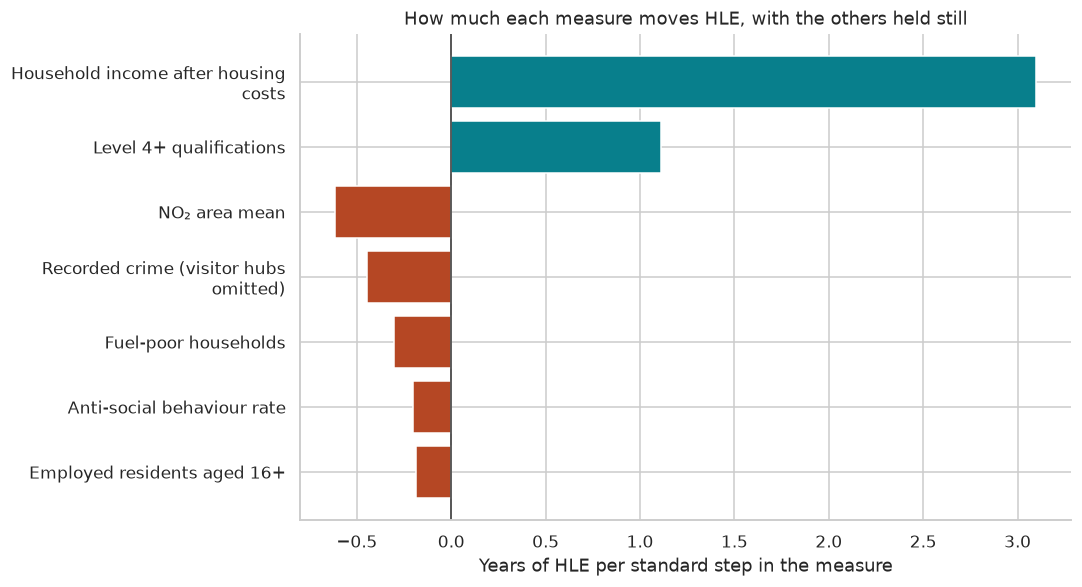

In [17]:
# One fit on all 654 areas, to read the weights. The test above is what says how well it predicts.
full_linear = Pipeline([("scale", StandardScaler()), ("linear", LinearRegression())]).fit(X, y)

# Measures are scaled, so each weight is years of HLE per standard step in that measure.
coefficients = pd.DataFrame({"measure": features, "label": [feature_labels[f] for f in features],
    "standardised_coefficient_years": full_linear.named_steps["linear"].coef_,
    "predictor_standard_deviation": full_linear.named_steps["scale"].scale_,
    "predictor_unit": [feature_units[f] for f in features], "area_count": len(y)})
coefficients = (coefficients.sort_values("standardised_coefficient_years", key=abs, ascending=False)
                .reset_index(drop=True))


fig, ax = plt.subplots(figsize=(10, 5.5))
positions = np.arange(len(coefficients))
colours = ["#087f8c" if value >= 0 else "#b54724" for value in coefficients["standardised_coefficient_years"]]
ax.barh(positions, coefficients["standardised_coefficient_years"], color=colours)
ax.set_yticks(positions, [textwrap.fill(label, 35) for label in coefficients["label"]])
ax.invert_yaxis()
ax.axvline(0, color="#333333", linewidth=1)
ax.set(title="How much each measure moves HLE, with the others held still",
       xlabel="Years of HLE per standard step in the measure", ylabel="")
fig.tight_layout()

display(coefficients.round(2))

save_figure(fig, "05_linear_coefficients.png")

Income dominates. One standard step up in income, about £5,000 a year after housing costs, goes with 3.1 more years in good health, with everything else held still. Qualifications come next at 1.1 years. NO₂ is the biggest of the rest at −0.6, so more polluted areas do a bit worse even at the same income. Crime, fuel poverty and anti-social behaviour all point the way I'd expect, but they're small.

Employment comes out slightly negative (−0.19), which looks wrong. It isn't saying work is bad for health. Employment is tangled up with income and qualifications, and once those are in the model there's very little left for it to explain. On its own, employment goes with higher HLE (a Spearman correlation of about +0.5).

### 12. Where the model gets it wrong

This is the bit I'm most interested in. A residual is an area's actual HLE minus what the model predicted for it. Positive means the area does better than its measures suggest. Negative means worse. Every prediction here comes from the authority-split test, so the model never saw the area's own authority.

A big residual doesn't prove there's a hidden cause. Some of it is noise in the HLE estimates, and some is a straight line being too simple. But it tells me where to look.

Ten areas doing better than predicted:


,area_code,local_area_name,authority_name,hle_average,out_of_fold_prediction,residual
0,E02002099,Central Solihull,Solihull,75.30,68.30,7.00
1,E02002083,Castle Bromwich East,Solihull,69.55,64.74,4.81
2,E02001905,Edgbaston South,Birmingham,69.80,65.36,4.44
3,E02002120,Ashmore,Walsall,66.30,62.32,3.98
4,E02002027,Withymoor Village,Dudley,70.95,67.03,3.92
5,E02001890,Edgbaston North,Birmingham,66.25,62.33,3.92
6,E02001859,Birchfield East,Birmingham,57.00,53.14,3.86
7,E02002026,Amblecote East,Dudley,66.95,63.24,3.71
8,E02006900,Bordesley,Birmingham,56.60,53.10,3.50
9,E02002089,Marston Green,Solihull,65.40,61.90,3.50


Ten areas doing worse than predicted:


,area_code,local_area_name,authority_name,hle_average,out_of_fold_prediction,residual
0,E02006895,Attwood Green,Birmingham,58.05,62.24,-4.19
1,E02007051,Lawley,Telford and Wrekin,64.25,68.41,-4.16
2,E02002174,Bradmore,Wolverhampton,64.05,68.16,-4.11
3,E02001938,Bournville East,Birmingham,63.55,67.48,-3.93
4,E02002178,Goldthorn Park,Wolverhampton,64.20,68.03,-3.83
5,E02001964,Henley Green,Coventry,55.90,59.72,-3.82
6,E02001951,Frankley,Birmingham,55.80,59.61,-3.81
7,E02001947,Druids Heath,Birmingham,54.20,57.97,-3.77
8,E02001930,Kings Heath,Birmingham,64.90,68.64,-3.74
9,E02001840,Perry Common College Road,Birmingham,54.60,58.32,-3.72


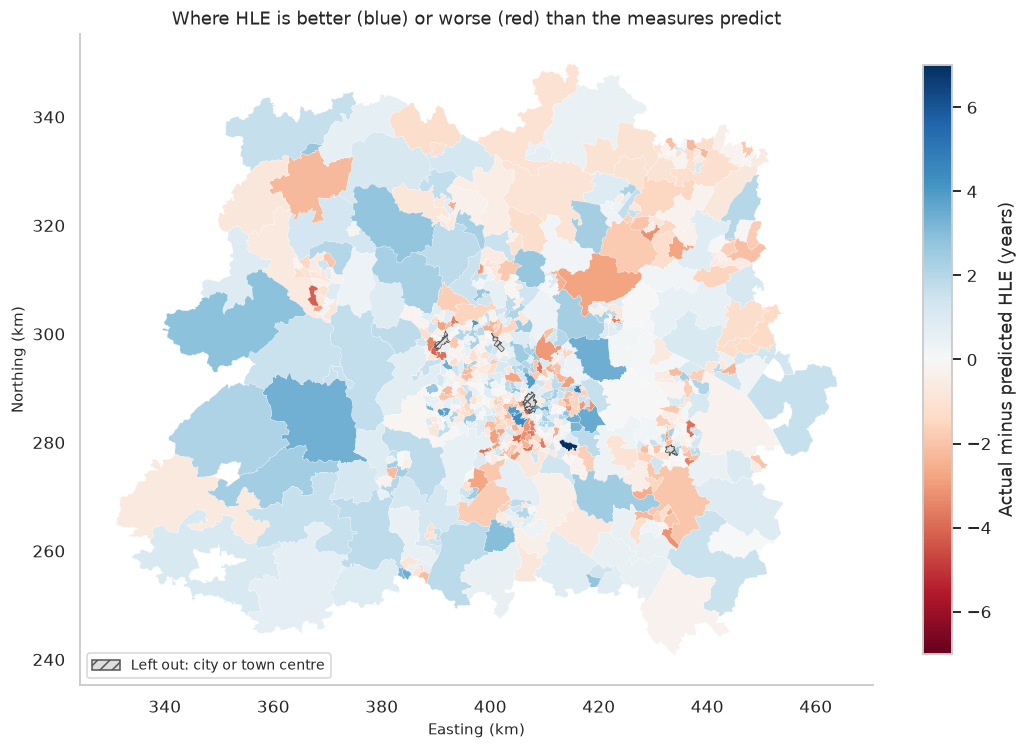

In [18]:
# Residual: actual HLE minus the prediction made without the area's own authority.
model_results["out_of_fold_prediction"] = linear_predictions
model_results["residual"] = y - linear_predictions

ranked_residuals = model_areas[["area_code", "local_area_name", "authority_name", "hle_average"]].merge(
    model_results[["area_code", "out_of_fold_prediction", "residual"]], on="area_code", validate="one_to_one")
largest_positive = ranked_residuals.nlargest(10, "residual")
largest_negative = ranked_residuals.nsmallest(10, "residual")


residual_map = boundaries_by_code.join(model_results.set_index("area_code")[["residual"]], how="left",
                                       validate="one_to_one")

# Centre the colours on zero so blue always means better than predicted and red worse.
limit = float(np.abs(model_results["residual"]).max())
residual_norm = TwoSlopeNorm(vmin=-limit, vcenter=0, vmax=limit)

fig, ax = plt.subplots(figsize=(10, 8))
residual_map.loc[residual_map["residual"].notna()].plot(column="residual", cmap="RdBu", norm=residual_norm, ax=ax,
                                                        edgecolor="#ffffff", linewidth=.15)
residual_map.loc[residual_map["residual"].isna()].plot(ax=ax, facecolor="#dddddd", edgecolor="#555555",
                                                       linewidth=.5, hatch="///")
fig.colorbar(plt.cm.ScalarMappable(norm=residual_norm, cmap="RdBu"), ax=ax, shrink=.7,
             label="Actual minus predicted HLE (years)")
ax.legend(handles=[Patch(facecolor="#dddddd", hatch="///", edgecolor="#555555", label="Left out: city or town centre")],
          loc="lower left", fontsize=9)
format_map(ax)
ax.set_title("Where HLE is better (blue) or worse (red) than the measures predict")
fig.tight_layout()

print("Ten areas doing better than predicted:")

display(largest_positive.reset_index(drop=True).round(2))

print("Ten areas doing worse than predicted:")

display(largest_negative.reset_index(drop=True).round(2))

save_figure(fig, "06_residual_map.png")

Central Solihull is the biggest positive residual by a distance: 75.3 years against a prediction of 68.3, so 7 years better than its measures suggest. Attwood Green in Birmingham is the biggest negative, about 4 years worse.

Some patterns jump out of the lists. Solihull turns up three times in the top ten doing better than predicted. A run of south Birmingham areas sits in the worse-than-predicted list: Frankley, Druids Heath, Kings Heath and Bournville East. And two low-HLE inner Birmingham areas, Birchfield East and Bordesley, do better than predicted by 3.5 to 4 years. They still have low HLE, just not as low as their income would suggest. I don't know why. Ethnic composition is one thing I left out of this model, and these are areas where it could matter. That's a question to test, not an answer.

To see whether whole authorities lean one way, I average the residuals by local authority.

In [19]:
# Does the model run high or low for whole authorities?
authority_residuals = (ranked_residuals.groupby("authority_name")["residual"]
                       .agg(areas="count", mean_residual="mean").reset_index())

# Ten areas or more, so a single odd area can't drive an authority's average.
authority_residuals = (authority_residuals.loc[authority_residuals["areas"].ge(10)]
                       .sort_values("mean_residual").reset_index(drop=True))

display(authority_residuals.round(2))

,authority_name,areas,mean_residual
0,South Derbyshire,12,-1.33
1,Warwick,15,-1.17
2,North West Leicestershire,13,-0.65
3,Wolverhampton,32,-0.60
4,Derby,16,-0.59
5,Telford and Wrekin,24,-0.47
6,Cannock Chase,13,-0.36
7,Birmingham,129,-0.35
8,Coventry,41,-0.25
9,Nuneaton and Bedworth,17,-0.11


Among authorities with at least ten areas, Shropshire, South Staffordshire, Wyre Forest, Redditch, Dudley and Solihull sit above the line on average. South Derbyshire, Warwick, North West Leicestershire, Wolverhampton and Derby sit below it. The averages are small, from about half a year to a year and a bit, but they're there. Something about these places, or something they share, isn't in my seven measures.

### 13. The look-alike pairs again

Now I can go back to the nine look-alike pairs and ask how much of each gap the model expected. For every big-gap pair I take the higher-HLE side and the lower-HLE side, and compare the gap the model predicted with the real one.

In [20]:
# Look-ups by area code for HLE, the prediction and the residual.
prediction_by_code = model_results.set_index("area_code")["out_of_fold_prediction"]
residual_by_code = model_results.set_index("area_code")["residual"]
hle_by_code = model_areas.set_index("area_code")["hle_average"]


pair_check = eligible_big_pairs[["area_a", "name_a", "area_b", "name_b"]].copy()
pair_check["same_group"] = ~different_cluster.to_numpy()

# Turn each pair round so the higher-HLE area always comes first.
a_higher = pair_check["area_a"].map(hle_by_code) >= pair_check["area_b"].map(hle_by_code)
pair_check["higher"] = np.where(a_higher, pair_check["name_a"], pair_check["name_b"])
pair_check["lower"] = np.where(a_higher, pair_check["name_b"], pair_check["name_a"])
higher_code = np.where(a_higher, pair_check["area_a"], pair_check["area_b"])
lower_code = np.where(a_higher, pair_check["area_b"], pair_check["area_a"])

# The real gap, the gap the model expected, and how much of the real gap that covers.
pair_check["actual_gap"] = hle_by_code.loc[higher_code].to_numpy() - hle_by_code.loc[lower_code].to_numpy()
pair_check["predicted_gap"] = (prediction_by_code.loc[higher_code].to_numpy()
                               - prediction_by_code.loc[lower_code].to_numpy())
pair_check["share_predicted"] = pair_check["predicted_gap"] / pair_check["actual_gap"]
pair_check["higher_residual"] = residual_by_code.loc[higher_code].to_numpy()
pair_check["lower_residual"] = residual_by_code.loc[lower_code].to_numpy()

# Widened: the better-off side beats its prediction and the worse-off side falls short of it.
pair_check["widened"] = (pair_check["higher_residual"] > 0) & (pair_check["lower_residual"] < 0)


pair_summary = pair_check.groupby("same_group").agg(
    pairs=("actual_gap", "size"), mean_actual_gap=("actual_gap", "mean"),
    mean_predicted_gap=("predicted_gap", "mean"), mean_share_predicted=("share_predicted", "mean"),
    share_widened=("widened", "mean")).rename(index={False: "Cross groups", True: "Same group"})

look_alike_check = (pair_check.loc[pair_check["same_group"], ["higher", "lower", "actual_gap", "predicted_gap",
                    "share_predicted", "higher_residual", "lower_residual"]]
                    .sort_values("actual_gap", ascending=False).reset_index(drop=True))

display(look_alike_check.round(2))

display(pair_summary.round(2))

,higher,lower,actual_gap,predicted_gap,share_predicted,higher_residual,lower_residual
0,Castle Bromwich East,Smith's Wood North,12.30,6.21,0.50,4.81,-1.29
1,Edgbaston South,Selly Oak,12.05,5.23,0.43,4.44,-2.37
2,Castle Bromwich East,Shard End,11.70,5.24,0.45,4.81,-1.65
3,Bulkington,Henley Green,11.50,6.51,0.57,1.18,-3.82
4,Castle Bromwich East,Smith's Wood South,11.45,4.92,0.43,4.81,-1.72
5,Coleshill,Smith's Wood North,10.50,7.62,0.73,1.60,-1.29
6,Kingswood,Warwick North,10.00,5.16,0.52,2.50,-2.33
7,Lyndon Green,Kent's Moat,9.70,3.94,0.41,2.85,-2.92
8,Coleshill,Smith's Wood South,9.65,6.33,0.66,1.60,-1.72


,pairs,mean_actual_gap,mean_predicted_gap,mean_share_predicted,share_widened
same_group,,,,,
Cross groups,83,11.41,9.21,0.81,0.6
Same group,9,10.98,5.68,0.52,1.0


For the nine look-alike pairs, the model expected gaps of about 4 to 8 years. The real gaps are 10 to 12. So the seven measures account for roughly half of each gap, and the other half is what I can't yet explain. In all nine, the better-off side does better than predicted and the worse-off side does worse.

Compare that with the 83 pairs that cross groups. There the model expects about 80% of the gap on average, and the residuals pull the gap wider in 60% of them.

Castle Bromwich East is in four of the nine pairs, and it's 4.8 years above its prediction every time. So the north Solihull patch is really one story: Castle Bromwich East does far better than its measures suggest, and the neighbours around it do a bit worse.

Two warnings to myself. I picked these pairs because their gaps are extreme, and an extreme gap is always partly noise in the estimates, so any model will undershoot it. And pairs in the same group have more similar measures by definition, so the model was always going to expect smaller gaps for them. Neither of those makes the gaps less real. They just mean the unexplained half isn't all a mystery waiting to be solved.

### 14. Is there still a pattern on the map?

Last check. Notebook 04 used Moran's I to measure how much neighbouring areas resemble each other on HLE. 0 means no pattern, and higher means neighbours look alike. If the seven measures have captured the geography, the residuals should have much less of it.

I use the same neighbour pairs and the same calculation as Notebook 04, minus the six areas that sit out. To check the result isn't chance, I shuffle the values around the map 999 times and see how often a shuffled map scores as high as the real one.

In [21]:
# Position of each pair's two areas in the list of 654, so they can index the neighbour grid.
included_codes = pd.Index(model_areas["area_code"])
restricted_pairs = all_pairs
a_index = included_codes.get_indexer(restricted_pairs["area_a"])
b_index = included_codes.get_indexer(restricted_pairs["area_b"])
assert (a_index >= 0).all() and (b_index >= 0).all()


# Neighbour grid: 1 where two areas share a boundary, then each row scaled to sum to 1.
n_areas = len(model_areas)
adjacency = np.zeros((n_areas, n_areas), dtype=float)
adjacency[a_index, b_index] = adjacency[b_index, a_index] = 1
degree = adjacency.sum(axis=1)
isolate_count = int((degree == 0).sum())
assert isolate_count == 0, "An area has no neighbours left once the six centres are removed."
weights = adjacency / degree[:, None]


# Notebook 04's calculation, wrapped up so I can run it on HLE and on the residuals.
def moran_reference(values):
    centred = np.asarray(values) - np.mean(values)
    denominator = float(centred @ centred)
    observed = float(n_areas / weights.sum() * (centred @ weights @ centred) / denominator)

    # Shuffle the values across the map 999 times: what would Moran's I look like with no pattern at all?
    # Shuffle in batches of 100 to keep it quick.
    rng = np.random.default_rng(SEED)
    permutation_i = np.empty(MORAN_PERMUTATIONS)
    for start in range(0, MORAN_PERMUTATIONS, 100):
        stop = min(start + 100, MORAN_PERMUTATIONS)
        shuffled = np.stack([rng.permutation(centred) for _ in range(stop - start)])
        permutation_i[start:stop] = (n_areas / weights.sum() * np.sum(shuffled * (shuffled @ weights.T), axis=1)
                                     / denominator)

    return {"moran_i": observed, "permutation_mean": float(permutation_i.mean()),
        "positive_permutation_reference": float((1 + np.sum(permutation_i >= observed)) / (MORAN_PERMUTATIONS + 1))}

In [22]:
hle_moran = moran_reference(y)
residual_moran = moran_reference(model_results["residual"].to_numpy())

spatial_summary = pd.DataFrame([
    {"measure": "Actual HLE", "area_count": n_areas, "neighbour_pairs": len(restricted_pairs), **hle_moran},
    {"measure": "Residual", "area_count": n_areas, "neighbour_pairs": len(restricted_pairs), **residual_moran}])

display(spatial_summary.round(3))

print(f"The measures take out {100 * (1 - residual_moran['moran_i'] / hle_moran['moran_i']):.0f}% "
      f"of the neighbour resemblance.")

,measure,area_count,neighbour_pairs,moran_i,permutation_mean,positive_permutation_reference
0,Actual HLE,654,1844,0.574,-0.002,0.001
1,Residual,654,1844,0.154,-0.002,0.001


The measures take out 73% of the neighbour resemblance.


HLE itself scores 0.57, close to Notebook 04's 0.576 (the six centres are missing here). The residuals score 0.15. So the seven measures take out about three-quarters of the neighbour resemblance, but not all of it. None of the 999 shuffled maps scored as high as the real residuals.

So neighbouring areas still tend to miss in the same direction. That fits with the authority pattern above: there's something local going on that my measures don't see.

## 15. Saving the results

Area results (group, prediction and residual), group profiles, HLE by group, model scores and weights all go to the Machine Learning folder, with a data dictionary and a summary file. The six city and town centres stay in the area file with blanks, so every one of the 660 areas is still accounted for. Everything overwrites on each run.

In [23]:
# One row for all 660 areas. The six centres stay, with blanks for the results they couldn't have.
area_ml_results = areas[["area_code", "local_area_name", "authority_code", "authority_name"]].merge(
    model_results, on="area_code", how="left", validate="one_to_one")
assert len(area_ml_results) == EXPECTED_AREAS and area_ml_results["area_code"].is_unique

analytical_columns = ["cluster_id", "cluster_label", "out_of_fold_prediction", "residual"]
is_excluded = area_ml_results["area_code"].isin(excluded["area_code"])
assert area_ml_results.loc[is_excluded, analytical_columns].isna().all().all()
assert area_ml_results.loc[~is_excluded, analytical_columns].notna().all().all()

tables = {"area_ml_results.csv": area_ml_results, "cluster_profiles.csv": cluster_profiles,
    "cluster_hle_summary.csv": cluster_hle_summary, "model_comparison.csv": model_comparison,
    "coefficients.csv": coefficients}
for filename, table in tables.items():
    save_csv(table, filename)

In [24]:
# What every saved column means, its unit, and what a blank means.
definitions = {
    "area_code": ("identifier", "Unique MSOA21 code retained from the joined table"),
    "local_area_name": ("text", "Saved familiar area name; no renaming"),
    "authority_code": ("identifier", "LAD22 code from the LSOA21-to-MSOA21-to-LAD22 lookup"),
    "authority_name": ("text", "Local authority name from the geography lookup"),
    "cluster_id": ("identifier", "K-means group numbered by mean income; HLE excluded from grouping"),
    "cluster_label": ("text",
        "Description of the two largest predictor-mean departures; HLE excluded from labelling"),
    "out_of_fold_prediction": ("years",
        "Linear prediction from the fold that holds out this area's whole local authority"),
    "residual": ("years", "Observed derived average HLE minus the grouped out-of-fold prediction"),
    "area_count": ("areas", "Number of included areas in the group or modelling population"),
    "measure": ("column name", "Predictor column from the saved provisional representatives"),
    "measure_label": ("text", "Saved readable predictor label"),
    "unit": ("text", "Unit of the original measure or HLE summary"),
    "mean": ("See unit", "Arithmetic mean in original units; group HLE means are descriptive"),
    "standardised_mean": ("standard deviations",
        "Group predictor mean minus overall included-area mean, divided by overall predictor standard deviation"),
    "count": ("areas", "Number of areas in the HLE group summary"),
    "median": ("years", "Median derived average HLE in the group"),
    "minimum": ("years", "Lowest observed derived average HLE in the group"),
    "maximum": ("years", "Highest observed derived average HLE in the group"),
    "model": ("text", "Training-mean baseline or plain linear regression"),
    "validation": ("text", "Grouped authority validation or the random-fold comparison"),
    "rmse_years": ("years", "Root mean squared error over pooled out-of-fold predictions"),
    "mae_years": ("years", "Mean absolute error over pooled out-of-fold predictions"),
    "r2": ("dimensionless", "Pooled out-of-fold R² against the overall observed mean; may be negative"),
    "label": ("text", "Saved readable predictor label"),
    "standardised_coefficient_years": ("years per predictor standard deviation",
        "Full-data linear coefficient with all other selected predictors held fixed; HLE is not standardised"),
    "predictor_standard_deviation": ("See predictor_unit",
        "Population standard deviation used by the full-data predictor scaler"),
    "predictor_unit": ("text", "Original predictor unit"),
}

dictionary_rows = []
for filename, table in tables.items():
    for column in table.columns:
        assert column in definitions, column
        unit, definition = definitions[column]
        missing_rule = ("Blank for the six excluded city and town centres"
                        if filename == "area_ml_results.csv" and column in analytical_columns
                        else "No missing values")
        dictionary_rows.append({"file": filename, "column": column, "unit": unit, "definition": definition,
                                "missing_rule": missing_rule})
ml_dictionary = pd.DataFrame(dictionary_rows)
save_csv(ml_dictionary, "ml_data_dictionary.csv")

In [25]:
# Every number the markdown quotes, in one file. Notebook 06 reads the folds from here.
summary = {"source_area_count": len(areas), "modelling_area_count": len(model_areas),
    "predictors": features, "predictor_count": len(features), "excluded_areas": excluded.to_dict("records"),
    "seed": SEED, "hle_period": str(wide["hle_period"].iloc[0]),
    "max_abs_spearman": max_spearman, "max_vif": float(vif_values.max()), "vif": vif_table.to_dict("records"),
    "chosen_k": chosen_k, "chosen_silhouette": chosen_silhouette, "k3_k4_difference": k3_k4_difference,
    "silhouette_scores": silhouette_table.to_dict("records"), "cluster_comparison": cluster_comparison.to_dict("records"),
    "bootstrap_resamples": BOOTSTRAPS, "bootstrap_mean_ari": stability_mean,
    "bootstrap_min_ari": float(min(stability_values)), "bootstrap_max_ari": float(max(stability_values)),
    "cluster_hle_between_share": cluster_hle_share,
    "cluster_labels": {str(k): v for k, v in cluster_label_lookup.items()},
    "cluster_hle_summary": cluster_hle_summary.to_dict("records"),
    "all_neighbour_pairs_cross_group_share": all_pairs_cross_share, "big_gap_eligible_pairs": len(eligible_big_pairs),
    "big_gap_different_cluster": big_pair_different, "big_gap_same_cluster": big_pair_same,
    "big_gap_unavailable_pairs": int((~eligible_big).sum()),
    "big_gap_pair_check": pair_summary.reset_index().to_dict("records"),
    "grouped_baseline": baseline_metrics, "grouped_linear": linear_metrics, "random_linear": random_metrics,
    "linear_beats_baseline": beats_baseline, "folds": fold_rows,
    "full_linear_intercept_years": float(full_linear.named_steps["linear"].intercept_),
    "coefficients": coefficients.to_dict("records"), "largest_positive_residuals": largest_positive.to_dict("records"),
    "largest_negative_residuals": largest_negative.to_dict("records"),
    "authority_residuals": authority_residuals.to_dict("records"),
    "retained_neighbour_pairs": len(restricted_pairs), "isolated_areas": isolate_count,
    "moran_permutations": MORAN_PERMUTATIONS,
    "hle_moran": hle_moran, "residual_moran": residual_moran,
    "output_folder": output_folder.relative_to(project_folder).as_posix(), "ethnicity_used": False}

summary_path = output_folder / "results_summary.json"
with summary_path.open("w", encoding="utf-8") as stream:
    json.dump(summary, stream, indent=2, ensure_ascii=False, allow_nan=False)
assert json.loads(summary_path.read_text()) == summary

print(f"Saved {len(tables) + 2} files and 6 figures to {output_folder.relative_to(project_folder).as_posix()}")

Saved 7 files and 6 figures to Data/Cleaned/Machine Learning


## What this tells me

I started with neighbours 14 to 16 years apart and asked why.

A big part of the answer is income, and the things that go with it. Seven measures predict HLE to within about a year and a half, in authorities the model never saw, and income does most of the work. Most of the big-gap neighbours are pairs where the two sides are different kinds of place: 90% of them cross groups, against 42% of neighbours generally. For those pairs the model expects about 80% of the gap.

It's not the whole answer. Some gaps are far bigger than the measures can account for. The clearest is Castle Bromwich East, nearly 5 years better than its measures suggest, sitting next to Smith's Wood and Shard End, which do a bit worse. There's also something local the measures miss. Areas in Solihull, Dudley and Shropshire tend to do better than predicted, and areas in south Birmingham, Wolverhampton and Warwick worse. The residuals still cluster on the map.

The 89% mostly confirms what you'd expect. I'm more drawn to the 11%.

### What I'm taking forward

- **The residuals.** Mapped, they're the most useful output here: the places where HLE doesn't match the measures.
- **Castle Bromwich East and its neighbours.** The clearest case of a gap far bigger than the measures account for.
- **The student areas.** Edgbaston South and Selly Oak get misread by the grouping, so I treat them separately.
- **Ethnic composition.** It goes back in as a test, to see whether it explains any of the inner-Birmingham residuals like Birchfield East and Bordesley.

### Limits, briefly

These are areas, not people, and links, not causes. HLE is an estimate with its own margin of error, and my average of men and women is my own measure, not an ONS one. The measures come from different years. And I chose the seven measures by looking at this same data, so the model has had a bit of help.